# Setup and Configuration


Purpose:
- Import required libraries
- Set deterministic behavior (seeds)
- Define device, paths, and constants
- Load train/test metadata

### Trackio installation 

In [1]:
# !pip install trackio
# import trackio


# # OUTPUT:- Successfully installed gradio-5.49.1 gradio-client-1.13.3 plotly-6.4.0 pydantic-2.11.10 pydantic-core-2.33.2 trackio-0.8.1

### Other necesaary imports

In [2]:
import numpy as np
import pandas as pd

import os
import random

import torch
import torch.nn as nn
import torch.optim as optim


import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader
import torch.nn.functional as F
import torchmetrics

import matplotlib.pyplot as plt
import kagglehub


### Huggingface setup

In [3]:
# ============================================================
# Huggingface Access Adding token to environment variable
# ============================================================

from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
import os
hf_token  = user_secrets.get_secret("HuggingFaceToken")
os.environ['HF_TOKEN '] = hf_token

### Device and seed configuration

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"✅ Device: {DEVICE}")


✅ Device: cuda


### Loading datasets

In [5]:
DATA_DIR  = "/kaggle/input/sep-25-dl-gen-ai-nppe-1/face_dataset"

train_dir = os.path.join(DATA_DIR, "train")
test_dir  = os.path.join(DATA_DIR, "test")

train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))

df_sample = pd.read_csv("/kaggle/input/sep-25-dl-gen-ai-nppe-1/face_dataset/sample_submission.csv")

In [6]:
print(train_df.shape)
print(test_df.shape)

(34708, 4)
(8677, 2)


In [7]:
df_sample.head()

,id,gender,age
0,0,0,28
1,1,0,52
2,2,1,17
3,3,1,59
4,4,1,31


### Data Visualization

- Gender Distribution
- Age Distribution

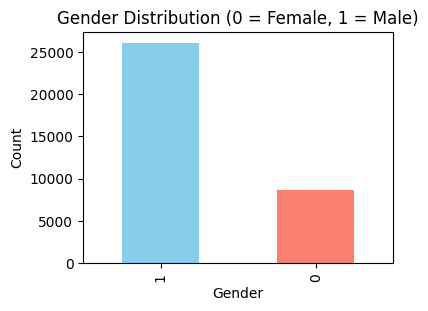

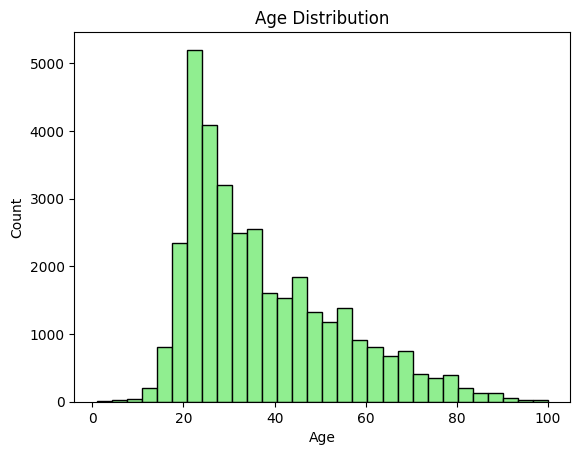

In [8]:
# ============================================================
# Gender distribution
# ============================================================

train_df['gender'].value_counts().plot(
    kind='bar', color=['skyblue', 'salmon'], figsize=(4,3)
)
plt.title("Gender Distribution (0 = Female, 1 = Male)")
plt.xlabel("Gender"); plt.ylabel("Count")
plt.show()


# ============================================================
# Age histogram
# ============================================================
plt.hist(train_df['age'], bins=30, color='lightgreen', edgecolor='black')
plt.title("Age Distribution"); plt.xlabel("Age"); plt.ylabel("Count")
plt.show()


# Data Preprocessing

Purpose:
- Define image size, batch size, transforms, and dataset
- Create train/val/test DataLoaders
- Visualize a few samples to verify correctness

### CONFIGURATION & BASIC PARAMETERS

In [9]:
IMAGE_SIZE = 224        
BATCH_SIZE = 64
NUM_WORKERS = 2
VAL_SPLIT = 0.2
PAD_DIGITS = 5          # to load images like 00001.jpg

### Image Transformation

Standard ImageNet mean/Std deviation

In [10]:
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.ConvertImageDtype(torch.float),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.Normalize(mean, std),
])

val_transforms = transforms.Compose([
    transforms.ConvertImageDtype(torch.float),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.Normalize(mean, std),
])

test_transforms = val_transforms

### Custom Dataset class

In [11]:
class FaceDataset(torch.utils.data.Dataset):
    """
    Dataset for age & gender prediction.
    Keeps 'id' values from CSV intact for submission,
    automatically converts filenames to 00001.jpg,
    and ensures every image has exactly 3 channels (RGB).
    """
    def __init__(self, df, images_folder, transform=None, has_labels=True):
        self.df = df.reset_index(drop=True)
        self.images_folder = images_folder
        self.transform = transform
        self.has_labels = has_labels

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_id = int(row['id'])
        fname = f"{img_id:0{PAD_DIGITS}d}.jpg"
        img_path = os.path.join(self.images_folder, fname)

        image = torchvision.io.read_image(img_path)  # [C, H, W]
        c = image.shape[0]

        # RGB format: handle 1, 3, or 4 channels safely
        if c == 1:
            image = image.repeat(3, 1, 1)       # grayscale → RGB
        elif c == 4:
            image = image[:3, :, :]             # RGBA → RGB

        if self.transform:
            image = self.transform(image)

        if self.has_labels:
            age = torch.tensor(row['age'], dtype=torch.float32)
            gender = torch.tensor(row['gender'], dtype=torch.float32)
        else:
            age = torch.tensor(-1.0)
            gender = torch.tensor(-1.0)

        return image, age, gender, img_id


### Dataset splitting (Train/ Val/ Test)

In [12]:
train_dataset_full = FaceDataset(train_df, train_dir, transform=train_transforms, has_labels=True)

# Deterministic split
num_samples = len(train_dataset_full)
indices = list(range(num_samples))
random.Random(SEED).shuffle(indices)
val_size = int(VAL_SPLIT * num_samples)
val_indices = indices[:val_size]
train_indices = indices[val_size:]

# Subsets for training and validation
train_dataset = torch.utils.data.Subset(train_dataset_full, train_indices)
val_dataset_full = FaceDataset(train_df, train_dir, transform=val_transforms, has_labels=True)
val_dataset = torch.utils.data.Subset(val_dataset_full, val_indices)

# Test dataset (no labels)
test_dataset = FaceDataset(test_df, test_dir, transform=test_transforms, has_labels=False)



### DataLoaders and Visualization of sample batch

In [13]:
# ============================================================
# DATALOADER
# ============================================================

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

print(f"📦 Datasets ready → Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")



📦 Datasets ready → Train: 27767 | Val: 6941 | Test: 8677



🖼️ Displaying few training samples to verify correctness:


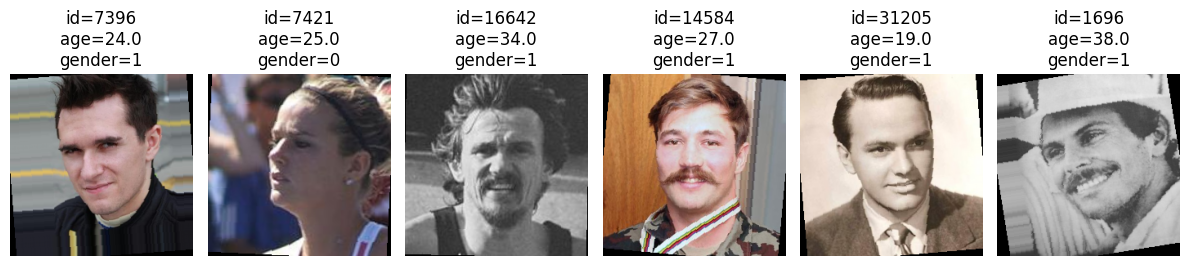

In [14]:
# ============================================================
# VISUALIZATION
# ============================================================

def unnormalize(img_tensor):
    """Undo normalization for display."""
    img = img_tensor.clone()
    for c in range(3):
        img[c] = img[c] * std[c] + mean[c]
    return torch.clamp(img, 0, 1)

def show_batch(dl, max_images=6):
    batch = next(iter(dl))
    imgs, ages, genders, ids = batch
    n = min(max_images, imgs.size(0))
    plt.figure(figsize=(12, 4))
    for i in range(n):
        img_disp = unnormalize(imgs[i]).permute(1, 2, 0).cpu().numpy()
        plt.subplot(1, n, i+1)
        plt.imshow(img_disp)
        plt.title(f"id={ids[i].item()}\nage={ages[i].item():.1f}\ngender={int(genders[i].item())}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()

print("\n🖼️ Displaying few training samples to verify correctness:")

show_batch(train_loader, max_images=6)

# Model Architecture

- Build a CNN model from scratch
- Use a pretrained model

### CNN model from scratch

In [15]:
# ============================================================
# MODEL BUILDING FROM SCRATCH
# ============================================================

class FaceNetScratch(nn.Module):
    """
    A simple CNN built from scratch for dual-output prediction:
      • Age (regression, 1 neuron)
      • Gender (binary classification, 1 neuron)
    Shared convolutional backbone + two separate heads.
    """
    def __init__(self):
        super(FaceNetScratch, self).__init__()

        # ---- Shared CNN feature extractor ----
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),       # 112×112

            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),       # 56×56

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),       # 28×28

            nn.Conv2d(128, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),       # 14×14
        )

        # Global pooling + fully connected layers
        self.flatten = nn.Flatten()
        self.shared_fc = nn.Sequential(
            nn.Linear(256 * 14 * 14, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
        )

        # ---- Dual Heads ----
        self.age_head = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 1)           # Regression output
        )

        self.gender_head = nn.Sequential(
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 1)           # Binary logits (no sigmoid)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(x)
        x = self.shared_fc(x)
        age_out = self.age_head(x)
        gender_out = self.gender_head(x)
        return age_out.squeeze(1), gender_out.squeeze(1)
        # returns shapes: [batch], [batch]

In [16]:
# ============================================================
# MODEL INITIALIZATION & SUMMARY
# ============================================================
model_scratch = FaceNetScratch().to(DEVICE)
print(model_scratch)

print("-"*60) #divider
print("-"*60) #divider

# Count parameters (verifying complexity)
num_params = sum(p.numel() for p in model_scratch.parameters() if p.requires_grad)
print(f"\n📊 Total trainable parameters: {num_params:,}")


FaceNetScratch(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=

In [17]:
# ============================================================
# DUMMY FORWARD PASS (SHAPE TEST)
# ============================================================
dummy_input = torch.randn(4, 3, IMAGE_SIZE, IMAGE_SIZE).to(DEVICE)
age_pred, gender_pred = model_scratch(dummy_input)

print(f"\n✅ Forward Pass Successful:")
print(f"Age Output Shape: {age_pred.shape}")
print(f"Gender Output Shape: {gender_pred.shape}")


✅ Forward Pass Successful:
Age Output Shape: torch.Size([4])
Gender Output Shape: torch.Size([4])


### Pretrained model - RESNET

In [18]:
# ============================================================
# LOAD PRETRAINED RESNET18
# ============================================================
from torchvision import models

def build_finetuned_resnet18():
    """
    Load pretrained ResNet18 and modify it to predict:
      • Age (regression)
      • Gender (binary classification)
    """
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

    # ---- Modify final layer ----
    in_features = model.fc.in_features  # typically 512
    model.fc = nn.Identity()            # remove original classification head

    # ---- Dual heads ----
    age_head = nn.Sequential(
        nn.Linear(in_features, 128),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(128, 1)
    )

    gender_head = nn.Sequential(
        nn.Linear(in_features, 128),
        nn.ReLU(),
        nn.Dropout(0.3),
        nn.Linear(128, 1)
    )

    # ---- Wrap everything into one module ----
    class FaceNetResNet(nn.Module):
        def __init__(self, backbone, age_head, gender_head):
            super().__init__()
            self.backbone = backbone
            self.age_head = age_head
            self.gender_head = gender_head

        def forward(self, x):
            x = self.backbone(x)
            age_out = self.age_head(x)
            gender_out = self.gender_head(x)
            return age_out.squeeze(1), gender_out.squeeze(1)

    return FaceNetResNet(model, age_head, gender_head)



# ============================================================
# INITIALIZE MODEL
# ============================================================
model_finetuned = build_finetuned_resnet18().to(DEVICE)
print(model_finetuned)

print("-"*60) #divider
print("-"*60) #divider

# Optionally freeze early layers (for faster training on small dataset)
for name, param in model_finetuned.backbone.named_parameters():
    param.requires_grad = False  # Freeze backbone initially

# Unfreeze last ResNet block for fine-tuning
for name, param in list(model_finetuned.backbone.layer4.named_parameters()):
    param.requires_grad = True



# ============================================================
# PARAMETER COUNT
# ============================================================
num_params_finetuned = sum(p.numel() for p in model_finetuned.parameters() if p.requires_grad)
print(f"\n📊 Trainable parameters (Finetuned Model): {num_params_finetuned:,}")



Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 160MB/s]


FaceNetResNet(
  (backbone): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, tr

# Training, Validating, and Loss Functions

In [19]:
# ============================================================
# LOSS FUNCTIONS, OPTIMIZER & METRICS
# ============================================================

# Regression loss for age
criterion_age = nn.MSELoss()

# Binary classification loss for gender (uses raw logits)
criterion_gender = nn.BCEWithLogitsLoss()

# Weighting between the two tasks
LAMBDA = 1.0

# Example optimizer (you can reuse for both models)
optimizer_scratch = optim.Adam(model_scratch.parameters(), lr=1e-3, weight_decay=1e-5)
optimizer_finetuned = optim.Adam(filter(lambda p: p.requires_grad, model_finetuned.parameters()),
                                 lr=1e-4, weight_decay=1e-5)

# TorchMetrics for convenience
metric_mae = torchmetrics.MeanAbsoluteError().to(DEVICE)
metric_acc = torchmetrics.Accuracy(task="binary").to(DEVICE)


In [20]:
# ============================================================
# TRAINING FUNCTION
# ============================================================
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, total_age_loss, total_gender_loss = 0, 0, 0
    metric_mae.reset()
    metric_acc.reset()

    for images, ages, genders, _ in loader:
        images, ages, genders = images.to(DEVICE), ages.to(DEVICE), genders.to(DEVICE)

        optimizer.zero_grad()
        age_out, gender_out = model(images)

        age_loss = criterion_age(age_out, ages)
        gender_loss = criterion_gender(gender_out, genders)
        loss = age_loss + LAMBDA * gender_loss

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_age_loss += age_loss.item() * images.size(0)
        total_gender_loss += gender_loss.item() * images.size(0)

        # metrics
        metric_mae.update(age_out, ages)
        metric_acc.update(torch.sigmoid(gender_out), genders)

    n = len(loader.dataset)
    return {
        "loss": total_loss / n,
        "age_loss": total_age_loss / n,
        "gender_loss": total_gender_loss / n,
        "mae": metric_mae.compute().item(),
        "acc": metric_acc.compute().item(),
    }


# ============================================================
# VALIDATION FUNCTION
# ============================================================

@torch.no_grad()
def validate_one_epoch(model, loader):
    model.eval()
    total_loss, total_age_loss, total_gender_loss = 0, 0, 0
    metric_mae.reset()
    metric_acc.reset()

    for images, ages, genders, _ in loader:
        images, ages, genders = images.to(DEVICE), ages.to(DEVICE), genders.to(DEVICE)
        age_out, gender_out = model(images)

        age_loss = criterion_age(age_out, ages)
        gender_loss = criterion_gender(gender_out, genders)
        loss = age_loss + LAMBDA * gender_loss

        total_loss += loss.item() * images.size(0)
        total_age_loss += age_loss.item() * images.size(0)
        total_gender_loss += gender_loss.item() * images.size(0)

        metric_mae.update(age_out, ages)
        metric_acc.update(torch.sigmoid(gender_out), genders)

    n = len(loader.dataset)
    return {
        "val_loss": total_loss / n,
        "val_age_loss": total_age_loss / n,
        "val_gender_loss": total_gender_loss / n,
        "val_mae": metric_mae.compute().item(),
        "val_acc": metric_acc.compute().item(),
    }

### Trackio Initialization for baseline CNN model

In [21]:
# # ============================================================
# # 5.3 TRACKIO INITIALIZATION
# # ============================================================
# trackio.init(
#     project="25-t3-nppe1",        
#     name="baseline-run",              
#     group="simple-cnn",               
#     space_id="Niraj-DS/dlgenai-nppe"  
# )


### Training baseline CNN model

In [22]:
# # ============================================================
# # 5.4 TRAINING LOOP 
# # ============================================================
# EPOCHS = 10  

# best_val_loss = float("inf")
# model_to_train = model_scratch        
# optimizer = optimizer_scratch


# for epoch in range(1, EPOCHS + 1):
#     train_metrics = train_one_epoch(model_to_train, train_loader, optimizer)
#     val_metrics = validate_one_epoch(model_to_train, val_loader)

#     # ✅ log metrics per epoch
#     trackio.log({
#         "epoch": epoch,
#         "train_loss": train_metrics["loss"],
#         "val_loss": val_metrics["val_loss"],
#         "train_mae": train_metrics["mae"],
#         "val_mae": val_metrics["val_mae"],
#         "train_acc": train_metrics["acc"],
#         "val_acc": val_metrics["val_acc"],
#     })

#     print(f"\nEpoch [{epoch}/{EPOCHS}]")
#     print(f"Train Loss: {train_metrics['loss']:.4f} | Val Loss: {val_metrics['val_loss']:.4f}")
#     print(f"MAE: {val_metrics['val_mae']:.4f} | Acc: {val_metrics['val_acc']:.4f}")

#     # Save best checkpoint
#     if val_metrics["val_loss"] < best_val_loss:
#         best_val_loss = val_metrics["val_loss"]
#         torch.save(model_to_train.state_dict(), "best_model.pt")
#         print("✅ Best model saved.")

# print("\n🎉 Training complete! Best validation loss:", best_val_loss)





"""
Output from the training

Epoch [1/10]
Train Loss: 217.2094 | Val Loss: 182.5369
MAE: 10.2389 | Acc: 0.7479
✅ Best model saved.

Epoch [2/10]
Train Loss: 176.3669 | Val Loss: 161.2081
MAE: 9.4338 | Acc: 0.7529
✅ Best model saved.

Epoch [3/10]
Train Loss: 161.5546 | Val Loss: 147.3630
MAE: 9.4416 | Acc: 0.7799
✅ Best model saved.

Epoch [4/10]
Train Loss: 148.3632 | Val Loss: 128.0533
MAE: 8.5434 | Acc: 0.7629
✅ Best model saved.

Epoch [5/10]
Train Loss: 141.5867 | Val Loss: 134.7192
MAE: 9.1329 | Acc: 0.7768

Epoch [6/10]
Train Loss: 133.2528 | Val Loss: 160.8167
MAE: 10.4352 | Acc: 0.7840

Epoch [7/10]
Train Loss: 126.1136 | Val Loss: 123.8813
MAE: 8.7120 | Acc: 0.7794
✅ Best model saved.

Epoch [8/10]
Train Loss: 124.9923 | Val Loss: 116.8299
MAE: 8.3921 | Acc: 0.7611
✅ Best model saved.

Epoch [9/10]
Train Loss: 117.4211 | Val Loss: 104.7873
MAE: 7.6895 | Acc: 0.8069
✅ Best model saved.

Epoch [10/10]
Train Loss: 114.2394 | Val Loss: 118.1476
MAE: 8.4542 | Acc: 0.8092

🎉 Training complete! Best validation loss: 104.78734809008238
"""


'\nOutput from the training\n\nEpoch [1/10]\nTrain Loss: 217.2094 | Val Loss: 182.5369\nMAE: 10.2389 | Acc: 0.7479\n✅ Best model saved.\n\nEpoch [2/10]\nTrain Loss: 176.3669 | Val Loss: 161.2081\nMAE: 9.4338 | Acc: 0.7529\n✅ Best model saved.\n\nEpoch [3/10]\nTrain Loss: 161.5546 | Val Loss: 147.3630\nMAE: 9.4416 | Acc: 0.7799\n✅ Best model saved.\n\nEpoch [4/10]\nTrain Loss: 148.3632 | Val Loss: 128.0533\nMAE: 8.5434 | Acc: 0.7629\n✅ Best model saved.\n\nEpoch [5/10]\nTrain Loss: 141.5867 | Val Loss: 134.7192\nMAE: 9.1329 | Acc: 0.7768\n\nEpoch [6/10]\nTrain Loss: 133.2528 | Val Loss: 160.8167\nMAE: 10.4352 | Acc: 0.7840\n\nEpoch [7/10]\nTrain Loss: 126.1136 | Val Loss: 123.8813\nMAE: 8.7120 | Acc: 0.7794\n✅ Best model saved.\n\nEpoch [8/10]\nTrain Loss: 124.9923 | Val Loss: 116.8299\nMAE: 8.3921 | Acc: 0.7611\n✅ Best model saved.\n\nEpoch [9/10]\nTrain Loss: 117.4211 | Val Loss: 104.7873\nMAE: 7.6895 | Acc: 0.8069\n✅ Best model saved.\n\nEpoch [10/10]\nTrain Loss: 114.2394 | Val Loss

In [23]:
# # ============================================================
# # 6.1 SAVE & VERIFY BEST MODEL - BASELINE CNN
# # ============================================================


# # Define path to save model (inside working directory)
# MODEL_PATH = "/kaggle/working/best_model.pt"

# # Save the best model weights
# torch.save(model_to_train.state_dict(), MODEL_PATH)
# print(f"✅ Model saved successfully at: {MODEL_PATH}")

# # Verify that the file exists and reloads properly
# reloaded_model = FaceNetScratch().to(DEVICE)
# reloaded_model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
# reloaded_model.eval()


In [24]:
# ============================================================
# TRACKIO LOGGING FINISHED - BASELINE CNN MODEL
# ============================================================

# trackio.finish()

In [25]:
# ============================================================
# KAGGLEHUB SETUP - BASELINE CNN MODEL
# ============================================================



# import kagglehub

# model_path = "/kaggle/working/best_model.pt"

# # ✅ Publish to KaggleHub
# Kaggleusername = 'nirajds'
# MODEL = 'baseline-cnn'
# FRAMEWORK = 'pytorch'
# VARIATION = 'm1'

# handle = f'{Kaggleusername}/{MODEL}/{FRAMEWORK}/{VARIATION}'

# kagglehub.model_upload(handle, model_path, version_notes='initial model')

# model_path = kagglehub.model_download(handle)
# print("✅ Model successfully published to KaggleHub!")
# print(model_path)



In [26]:
# ============================================================
#  INFERENCE & SUBMISSION - BASELINE CNN
# ============================================================

# 1️⃣ Load trained model
model_infer = FaceNetScratch().to(DEVICE)
model_infer.load_state_dict(torch.load("/kaggle/input/baseline-cnn/pytorch/m1/1/best_model.pt", map_location=DEVICE))
model_infer.eval()
print("✅ Loaded best_model.pt for inference.")


# 2️⃣ Define test dataset and loader
test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ConvertImageDtype(torch.float32),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

test_dataset = FaceDataset(
    df=test_df,
    images_folder=test_dir,
    transform=test_transform,
    has_labels=False
)

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"✅ Test set ready — total images: {len(test_dataset)}")



✅ Loaded best_model.pt for inference.
✅ Test set ready — total images: 8677


In [27]:
# ============================================================
# RUNNING INFERENCE - BASELINE CNN
# ============================================================
pred_ages = []
pred_genders = []
img_ids = []

with torch.no_grad():
    for images, _, _, ids in test_loader:
        images = images.to(DEVICE)

        age_out, gender_out = model_infer(images)

        # Age predictions — raw regression output
        ages = age_out.cpu().numpy().tolist()

        # Gender predictions — sigmoid → 0/1
        genders = (torch.sigmoid(gender_out) > 0.5).long().cpu().numpy().tolist()

        pred_ages.extend(ages)
        pred_genders.extend(genders)
        img_ids.extend(ids.tolist())

print(f"✅ Inference done — {len(pred_ages)} predictions generated.")



✅ Inference done — 8677 predictions generated.


In [28]:
# ============================================================
# SUBMISSION FILE - BASELINE CNN
# ============================================================

# # 4️⃣ Create submission DataFrame
# submission_df = pd.DataFrame({
#     "id": img_ids,
#     "age": pred_ages,
#     "gender": pred_genders
# }).sort_values("id").reset_index(drop=True)

# # Save to CSV
# submission_path = "/kaggle/working/submission.csv"
# submission_df.to_csv(submission_path, index=False)

# print(f"✅ Submission file created at: {submission_path}")
# submission_df.head()


# # Score obtained - 0.5

#### Resnet Model Config

In [29]:
# # ============================================================
# # TRACKIO INITIALIZATION - RESNET MODEL
# # ============================================================
# trackio.init(
#     project="25-t3-nppe1",        
#     name="resnet-run",              
#     group="pretrained-model",               
#     space_id="Niraj-DS/dlgenai-nppe"  
# )


In [30]:
# # ============================================================
# # Training Config - RESNET MODEL
# # ============================================================
# EPOCHS = 15
# best_val_loss = float("inf")

# # ✅ Use finetuned ResNet18
# model_to_train = model_finetuned
# optimizer = optimizer_finetuned

# # ============================================================
# # Training Loop - RESNET MODEL
# # ============================================================
# for epoch in range(1, EPOCHS + 1):
#     train_metrics = train_one_epoch(model_to_train, train_loader, optimizer)
#     val_metrics = validate_one_epoch(model_to_train, val_loader)

#     # ✅ Log metrics to TrackIO
#     trackio.log({
#         "epoch": epoch,
#         "train_loss": train_metrics["loss"],
#         "val_loss": val_metrics["val_loss"],
#         "train_mae": train_metrics["mae"],
#         "val_mae": val_metrics["val_mae"],
#         "train_acc": train_metrics["acc"],
#         "val_acc": val_metrics["val_acc"],
#     })

#     # 🧾 Console output
#     print(f"\nEpoch [{epoch}/{EPOCHS}]")
#     print(f"Train Loss: {train_metrics['loss']:.4f} | Val Loss: {val_metrics['val_loss']:.4f}")
#     print(f"MAE: {val_metrics['val_mae']:.4f} | Acc: {val_metrics['val_acc']:.4f}")

#     # ✅ Save best checkpoint
#     if val_metrics["val_loss"] < best_val_loss:
#         best_val_loss = val_metrics["val_loss"]
#         torch.save(model_to_train.state_dict(), "/kaggle/working/best_model_finetuned.pt")
#         print("✅ Best finetuned model saved.")



# print("\n🎉 Finetuned training complete! Best validation loss:", best_val_loss)





"""
Result

Epoch [1/15]
Train Loss: 205.4598 | Val Loss: 98.0002
MAE: 7.2613 | Acc: 0.8555
✅ Best finetuned model saved.

Epoch [2/15]
Train Loss: 100.1381 | Val Loss: 89.4777
MAE: 7.0199 | Acc: 0.8725
✅ Best finetuned model saved.

Epoch [3/15]
Train Loss: 91.1035 | Val Loss: 86.6231
MAE: 6.7794 | Acc: 0.8847
✅ Best finetuned model saved.

Epoch [5/15]
Train Loss: 76.6112 | Val Loss: 88.0214
MAE: 6.7119 | Acc: 0.8912

Epoch [6/15]
Train Loss: 70.5136 | Val Loss: 83.7555
MAE: 6.7417 | Acc: 0.8951

Epoch [7/15]
Train Loss: 64.5269 | Val Loss: 87.6856
MAE: 6.7255 | Acc: 0.8963

Epoch [8/15]
Train Loss: 59.7434 | Val Loss: 83.8944
MAE: 6.6372 | Acc: 0.8966

Epoch [9/15]
Train Loss: 57.3421 | Val Loss: 84.1691
MAE: 6.7147 | Acc: 0.8989

Epoch [10/15]
Train Loss: 52.9535 | Val Loss: 83.9470
MAE: 6.5862 | Acc: 0.8989

Epoch [11/15]
Train Loss: 50.5453 | Val Loss: 82.3313
MAE: 6.6401 | Acc: 0.9006
✅ Best finetuned model saved.

Epoch [12/15]
Train Loss: 47.0578 | Val Loss: 83.2336
MAE: 6.6453 | Acc: 0.9036

Epoch [13/15]
Train Loss: 46.7350 | Val Loss: 84.9337
MAE: 6.6643 | Acc: 0.9002

Epoch [14/15]
Train Loss: 43.8373 | Val Loss: 84.9419
MAE: 6.6773 | Acc: 0.8930

Epoch [15/15]
Train Loss: 42.1878 | Val Loss: 81.2999
MAE: 6.5979 | Acc: 0.9101
✅ Best finetuned model saved.

🎉 Finetuned training complete! Best validation loss: 81.29989961910756
"""

'\nResult\n\nEpoch [1/15]\nTrain Loss: 205.4598 | Val Loss: 98.0002\nMAE: 7.2613 | Acc: 0.8555\n✅ Best finetuned model saved.\n\nEpoch [2/15]\nTrain Loss: 100.1381 | Val Loss: 89.4777\nMAE: 7.0199 | Acc: 0.8725\n✅ Best finetuned model saved.\n\nEpoch [3/15]\nTrain Loss: 91.1035 | Val Loss: 86.6231\nMAE: 6.7794 | Acc: 0.8847\n✅ Best finetuned model saved.\n\nEpoch [5/15]\nTrain Loss: 76.6112 | Val Loss: 88.0214\nMAE: 6.7119 | Acc: 0.8912\n\nEpoch [6/15]\nTrain Loss: 70.5136 | Val Loss: 83.7555\nMAE: 6.7417 | Acc: 0.8951\n\nEpoch [7/15]\nTrain Loss: 64.5269 | Val Loss: 87.6856\nMAE: 6.7255 | Acc: 0.8963\n\nEpoch [8/15]\nTrain Loss: 59.7434 | Val Loss: 83.8944\nMAE: 6.6372 | Acc: 0.8966\n\nEpoch [9/15]\nTrain Loss: 57.3421 | Val Loss: 84.1691\nMAE: 6.7147 | Acc: 0.8989\n\nEpoch [10/15]\nTrain Loss: 52.9535 | Val Loss: 83.9470\nMAE: 6.5862 | Acc: 0.8989\n\nEpoch [11/15]\nTrain Loss: 50.5453 | Val Loss: 82.3313\nMAE: 6.6401 | Acc: 0.9006\n✅ Best finetuned model saved.\n\nEpoch [12/15]\nTrai

In [31]:
# # ============================================================
# # SAVE & VERIFY BEST MODEL - RESNET MODEL
# # ============================================================

# # Define path to save model (inside working directory)
# MODEL_PATH = "/kaggle/working/best_model_finetuned.pt"

# # Save the best model weights
# torch.save(model_to_train.state_dict(), MODEL_PATH)
# print(f"✅ Finetuned model saved successfully at: {MODEL_PATH}")

# # Verify that the file exists and reloads properly
# reloaded_model = build_finetuned_resnet18().to(DEVICE)
# reloaded_model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))
# reloaded_model.eval()

# print("✅ Reload test passed — model architecture and weights loaded successfully.")


In [32]:
# # # ============================================================
# # KAGGLEHUB - RESNET MODEL
# # # ============================================================


# model_path_pretrained = "/kaggle/working/best_model_finetuned.pt"

# # ✅ Publish to KaggleHub
# Kaggleusername = 'nirajds'
# MODEL = 'pretrained_run'
# FRAMEWORK = 'pytorch'
# VARIATION = 'm1'

# handle_pretrained = f'{Kaggleusername}/{MODEL}/{FRAMEWORK}/{VARIATION}'

# kagglehub.model_upload(handle_pretrained, model_path_pretrained, version_notes='resnet-model')

# model_path = kagglehub.model_download(handle_pretrained)
# print("✅ Model successfully published to KaggleHub!")
# print(model_path)



In [33]:
# trackio.finish()

In [34]:
# ============================================================
# INFERENCE & SUBMISSION - FINETUNED MODEL
# ============================================================



# 1️⃣  Load pretrained model architecture
model_infer_pret = build_finetuned_resnet18().to(DEVICE)
model_infer_pret.load_state_dict(torch.load("/kaggle/input/pretrained_run/pytorch/m1/1/best_model_finetuned.pt", map_location=DEVICE))
model_infer_pret.eval()
print("✅ Loaded pretrained ResNet18 model for inference.")


# ============================================================
# TEST DATASET LOADING
# ============================================================

test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ConvertImageDtype(torch.float32),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

test_dataset = FaceDataset(
    df=test_df,
    images_folder=test_dir,
    transform=test_transform,
    has_labels=False
)

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
print(f"✅ Test set ready — total images: {len(test_dataset)}")


# ============================================================
# INFERENCE
# ============================================================

pred_ages = []
pred_genders = []
img_ids = []

model_infer_pret.eval()
with torch.no_grad():
    for images, _, _, ids in test_loader:
        images = images.to(DEVICE)
        age_out, gender_out = model_infer_pret(images)

        # 🔢 Convert to numpy
        ages = age_out.cpu().numpy().tolist()
        genders = (torch.sigmoid(gender_out) > 0.5).long().cpu().numpy().tolist()

        pred_ages.extend(ages)
        pred_genders.extend(genders)
        img_ids.extend(ids.tolist())

print(f"✅ Inference done — {len(pred_ages)} predictions generated.")





✅ Loaded pretrained ResNet18 model for inference.
✅ Test set ready — total images: 8677
✅ Inference done — 8677 predictions generated.


In [35]:
# ============================================================
# SUBMISSION FILE - RESNET
# ============================================================

submission_df = pd.DataFrame({
    "id": img_ids,
    "age": pred_ages,
    "gender": pred_genders
})

# Sort by ID to match sample_submission.csv order
submission_df = submission_df.sort_values(by="id").reset_index(drop=True)

submission_path = "/kaggle/working/submission.csv"
submission_df.to_csv(submission_path, index=False)
print(f"✅ Submission file created at: {submission_path}")

# Show a preview
print(submission_df.head())

✅ Submission file created at: /kaggle/working/submission.csv
   id        age  gender
0   0  36.504650       1
1   1  27.688660       0
2   2  29.425865       1
3   3  25.465549       1
4   4  64.189735       1
